# Chance level IM vs IP amb Matriu de covariàncies, espai tangent amb Riemann i LDA

**Tres preguntes:**
1. Quants epochs calen (aprox.) per superar el chance level en IM vs IP?
2. Per a cada elèctrode, a partir de quin instant se supera chance level?
3. A nivell de grup, on i quan podem afirmar que l'accuracy supera chance?

**Metodologia:**
- Surrogate per permutació d'etiquetes, **per subjecte × elèctrode × finestra temporal**.
- ΔAcc = Acc_real(t) − Acc_chance(t)
- Contrast de grup: paired t-test one-tailed vectoritzat + FDR per cel·la (canal, t).
- Paral·lelisme: `joblib.Parallel` (N_JOBS) sobre subjectes.
- Els resultats intermedis amb cost computacional alt es desen a disc per evitar recalcular si el kernel cau.


In [8]:
import warnings
from pathlib import Path
from scipy.signal import hilbert
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import numpy as np
import pandas as pd
from joblib import Parallel, delayed, cpu_count
from scipy.stats import ttest_rel
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# !pip install -q pyriemann
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
    drive.mount("/content/drive")
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
ANALYSIS_DIR = ANALYSIS_ROOT / "im_vs_ip_riemann"
CACHE_DIR = ANALYSIS_DIR / "cache"
TABLES_DIR = ANALYSIS_DIR / "tables"
FIGURES_DIR = ANALYSIS_DIR / "figures"
for folder in (DATA_DIR, ANALYSIS_ROOT, ANALYSIS_DIR, CACHE_DIR, TABLES_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

COND_EVENTS = {
    "Incongruent_Mixt": ["event_7", "event_8"],
    "Incongruent_Pur": ["event_3", "event_4", "event_5", "event_6"],
}

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Dades: {DATA_DIR}")
print(f"Resultats: {ANALYSIS_DIR}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")
print(f"Cores disponibles: {cpu_count()}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann
Fitxers .fif trobats: 47
Cores disponibles: 8


## Configuració

## Super-Covariança: Fusió Multi-Xarxa (Theta + Alfa)

1. **Filtratge independent:** Theta (5–7 Hz, 9 canals frontomedial) i Alfa (8–12 Hz, 13 canals parieto-occipital)
2. **Concatenació:** Forma (trials, 22, times) ← stack en axis=1
3. **Covariança 22×22:** Per subjecte, per trial, per finestra temporal
   - **Diagonal:** Potència intra-banda (Theta²_ch1, ..., Alfa²_ch1, ...)
   - **Off-diagonal:** Covariàncies creuades **Theta ↔ Alfa** (clau!)
4. **Espai tangent de Riemann:** LDA discrimina com cau l'energia Alfa **quan puja** l'energia Theta
   - Quan la ACC detalla error (theta ↑) → supressió visual (alfa ↓)

In [9]:
TASK_TAG = "im_vs_ip_riemann_fused"
RECALCULAR_CHANCE_LEVEL = False
ANALYSIS_WINDOW = (0.0, 1.5)

# ========== SUPER-COVARIÀNCIA: Fusió Multi-Xarxa (Theta + Alfa) ==========
# Theta (frontomedial): ~9 canals per captar error detection (ACC)
# Alfa (parieto-occipital): ~13 canals per captar visual feedback suppression
# Concatenació en l'eix dels canals (axis=1) → (trials, 22, times)
# Covariància 22×22 captura correlacions creuades (fora de la diagonal principal)
# L'espai tangent de Riemann discrimina com cau l'energia alfa quan puja l'energia theta
TARGET_BANDS_CLUSTERS = {
    "theta": ["Fp1", "Fp2", "Fz", "F1", "F2", "FCz", "FC1", "FC2", "Cz"],  # 9 frontomedial
    "alpha": ["Pz", "P1", "P2", "P3", "P4", "P7", "P8", "Oz", "O1", "O2", "PO3", "PO4", "POz"],  # 13 parieto-occipital
}

BAND_RANGES = {
    "theta": (5.0, 7.0),
    "alpha": (8.0, 12.0),
}
# Mode: "fused" = concatenate Theta + Alfa en l'eix dels canals
CHANNEL_MODE = ["fused"]

# Mapa de condicions com a 01_exploració_dades.ipynb: codis + tags event_<codi>
COND_EVENTS_CODES = {
    "Incongruent_Pur": [3, 4, 5, 6],
    "Incongruent_Mixt": [7, 8],
}
COND_EVENTS = {
    cond_name: [f"event_{code}" for code in codes_list] for cond_name, codes_list in COND_EVENTS_CODES.items()
}

# Subjectes: sempre des de CSV, i retallats amb MAX_SUBJECTS
SELECTED_SUBJECTS_CSV = PROJECT_DIR / "04_Anàlisi" / "01_exploracio" / "tables" / "subjectes_seleccionats_im_vs_ip.csv"
MAX_SUBJECTS = 30  # None = tots els del CSV
UNDERSAMPLE_CLASSES = True  # balanceja IM/IP per subjecte

# Directoris de sortida
RESULTS_DIR = ANALYSIS_DIR
CACHE_EPOCHS_DIR = CACHE_DIR
CACHE_MAP_FILE = CACHE_DIR / f"tensors_map_{TASK_TAG}.npz"
EPOCHS_CSV = TABLES_DIR / "epochs_grid_riemann.csv"
ONSET_CSV = TABLES_DIR / "onset_summary_riemann.csv"

# Mapa temps×elèctrode
MAP_WINDOW_SEC = 0.500  # amplada finestra temporal (s)
MAP_STEP_SEC = 0.1  # pas (s) - incrementat lleugerament per eficiència temporal
MAP_CV_MAX_SPLITS = 3

# Surrogate
N_PERM_SURROGATE = 200

# Graella epochs
EPOCHS_GRID = [x for x in range(20, 200, 20)]
N_REPEATS_EPOCHS = 10
N_JOBS = cpu_count() - 2 if cpu_count() > 4 else cpu_count()

RANDOM_SEED = 42

print(f"BASE_DIR: {BASE_DIR}")
print(f"ANALYSIS_ROOT: {ANALYSIS_ROOT}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"CACHE_DIR: {CACHE_DIR}")
print(f"TABLES_DIR: {TABLES_DIR}")
print(f"FIGURES_DIR: {FIGURES_DIR}")
print(f"SELECTED_SUBJECTS_CSV: {SELECTED_SUBJECTS_CSV}")
print(f"TARGET_BANDS_CLUSTERS: {TARGET_BANDS_CLUSTERS}")
print(f"BAND_RANGES: {BAND_RANGES}")
print(f"COND_EVENTS_CODES: {COND_EVENTS_CODES}")
print(f"COND_EVENTS (tags): {COND_EVENTS}")

BASE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
ANALYSIS_ROOT: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
RESULTS_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann
CACHE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache
TABLES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\tables
FIGURES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\figures
SELECTED_SUBJECTS_CSV: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\subjectes_seleccionats_im_vs_ip.csv
TARGET_BANDS_CLUSTERS: {'theta': ['Fp1', 'Fp2', 'Fz', 'F1', 'F2', 'FCz', 'FC1', 'FC2', 'Cz'], 'alpha': ['Pz', 'P1', 'P2', 'P3', 'P4', 'P7', 'P8', 'Oz', 'O1', 'O2', 'P

## 1. Càrrega de dades

In [10]:
def load_chance_epochs():
    """Carrega els subjectes, filtra les bandes i selecciona els clústers de canals requerits.

    Per a la FUSIÓ MULTI-XARXA (Super-Covariança):
    - Filtra Theta i Alfa independentment
    - Concatena els canals en l'eix dels canals (axis=1) per captar correlacions creuades
    - Retorna X_dict['fused'] = (trials, theta_chs + alfa_chs, times)
    """
    df_sel = pd.read_csv(SELECTED_SUBJECTS_CSV)

    subject_ids = df_sel["subjecte"].dropna().astype(str).tolist()
    subject_ids = list(dict.fromkeys(subject_ids))
    if MAX_SUBJECTS is not None:
        subject_ids = subject_ids[:MAX_SUBJECTS]
    print(f"Subjectes seleccionats a carregar: {len(subject_ids)}")

    fif_by_subject = {p.stem: p for p in DATA_FILES}

    # Estructura: X_blocks["theta"] = [(trials, channels, times), ...], X_blocks["alpha"] = [...]
    X_blocks = {band: [] for band in TARGET_BANDS_CLUSTERS}
    y_blocks = []
    subj_blocks = []
    skipped = []

    # Store dynamic channel names available per band
    avail_ch_names = {band: [] for band in TARGET_BANDS_CLUSTERS}
    first_subject_times = None

    for subj_name in subject_ids:
        fif_path = fif_by_subject.get(subj_name)
        if fif_path is None:
            skipped.append(f"{subj_name}: fitxer .fif no trobat")
            continue

        ep = mne.read_epochs(fif_path, preload=False)
        ep.load_data()  # Carrega les dades després de revisar els canals per estalviar memòria si es salta el subjece

        for ch_idx, ch_name in enumerate(ep.ch_names):
            if ep.info["chs"][ch_idx]["unit"] == 0:
                ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
        ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))

        # La selecció real es fa pels codis de 01; els tags es mantenen només com a referència.
        im_codes = COND_EVENTS_CODES["Incongruent_Mixt"]
        ip_codes = COND_EVENTS_CODES["Incongruent_Pur"]
        events = ep.events[:, 2]
        im_mask = np.isin(events, im_codes)
        ip_mask = np.isin(events, ip_codes)
        if not im_mask.any() or not ip_mask.any():
            skipped.append(
                f"{fif_path.name}: falten codis requerits (IM={int(im_mask.sum())}, IP={int(ip_mask.sum())})"
            )
            continue
        ep = ep[im_mask | ip_mask].copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])

        if first_subject_times is None:
            first_subject_times = np.array(ep.times, dtype=np.float32)

        events = ep.events[:, 2]
        y_s = np.where(np.isin(events, im_codes), 0, 1).astype(np.int8)

        n_im, n_ip = int((y_s == 0).sum()), int((y_s == 1).sum())
        if min(n_im, n_ip) == 0:
            skipped.append(f"{fif_path.name}: classe buida (IM={n_im}, IP={n_ip})")
            continue

        if UNDERSAMPLE_CLASSES:
            n_min = min(n_im, n_ip)
            rng = np.random.default_rng(RANDOM_SEED + sum(bytearray(subj_name.encode("utf-8"))))
            idx_im = np.where(y_s == 0)[0]
            idx_ip = np.where(y_s == 1)[0]
            keep_idx = np.concatenate(
                [rng.choice(idx_im, n_min, replace=False), rng.choice(idx_ip, n_min, replace=False)]
            )
            rng.shuffle(keep_idx)
            ep = ep[keep_idx]
            y_s = y_s[keep_idx]

        valid_for_subject = True
        subj_band_data = {}
        for band, target_channels in TARGET_BANDS_CLUSTERS.items():
            avail_chs = [ch for ch in target_channels if ch in ep.ch_names]
            if len(avail_chs) < len(target_channels) * 0.5:  # Require at least half the cluster
                skipped.append(f"{fif_path.name}: massa pocs canals per al cluster {band}")
                valid_for_subject = False
                break

            avail_ch_names[band] = avail_chs

            l_freq, h_freq = BAND_RANGES[band]
            ep_band = ep.copy().pick(avail_chs)
            ep_band._data = np.ascontiguousarray(ep_band._data)
            ep_band.filter(
                l_freq=l_freq,
                h_freq=h_freq,
                method="fir",
                phase="zero-double",
                verbose=False,
            )
            subj_band_data[band] = ep_band.get_data().astype(np.float32)

        if not valid_for_subject:
            continue

        for band in TARGET_BANDS_CLUSTERS:
            X_blocks[band].append(subj_band_data[band])

        y_blocks.append(y_s)
        subj_blocks.extend([subj_name] * len(y_s))

    # Concatena per banda primer
    X_dict = {band: np.concatenate(blocks, axis=0) for band, blocks in X_blocks.items()}

    # ===== FUSIÓ MULTI-XARXA =====
    # Concatena Theta i Alfa en l'eix dels canals (axis=1)
    # Forma: (trials, theta_channels + alfa_channels, times)
    if "theta" in X_dict and "alpha" in X_dict:
        X_fused = np.concatenate([X_dict["theta"], X_dict["alpha"]], axis=1)
        X_dict["fused"] = X_fused
        n_theta_chs = X_dict["theta"].shape[1]
        n_alpha_chs = X_dict["alpha"].shape[1]
        print(f"🔗 Multi-network fusion: Theta ({n_theta_chs}) + Alfa ({n_alpha_chs}) = {X_fused.shape[1]} channels")

    y = np.concatenate(y_blocks, axis=0)
    subj_list = np.array(subj_blocks, dtype=object)

    print(f"Mostres totals: {len(y)} | IM={(y==0).sum()} | IP={(y==1).sum()}")
    print(f"Subjectes carregats: {len(np.unique(subj_list))}")
    for band in TARGET_BANDS_CLUSTERS:
        print(f"Canals clúster {band}: {avail_ch_names[band]}")

    if skipped:
        print("Omesos:")
        for m in skipped:
            print(f"  {m}")

    return X_dict, y, subj_list, avail_ch_names, first_subject_times


X_dict, y, subj_list, ch_names_dict, times = load_chance_epochs()

Subjectes seleccionats a carregar: 30
🔗 Multi-network fusion: Theta (9) + Alfa (13) = 22 channels
Mostres totals: 5950 | IM=2975 | IP=2975
Subjectes carregats: 30
Canals clúster theta: ['Fp1', 'Fp2', 'Fz', 'F1', 'F2', 'FCz', 'FC1', 'FC2', 'Cz']
Canals clúster alpha: ['Pz', 'P1', 'P2', 'P3', 'P4', 'P7', 'P8', 'Oz', 'O1', 'O2', 'PO3', 'PO4', 'POz']


## 2. Funcions de CV i surrogate

### Decisions de disseny

**Per quin nivell es calcula el surrogate?**  
El surrogate s'avalua **a la mateixa finestra temporal** que l'accuracy real.  
D'aquesta manera, ΔAcc(t) = Acc_real(t) − Acc_chance(t) és una comparació neta:
ambdues xifres es basen en les mateixes mostres temporals i el mateix classificador.

**Paired t-test de grup:**  
Per a cada cel·la (canal, t) comparem el vector d'Acc_real dels subjectes vs el vector
d'Acc_chance. Amb N≥6 subjectes vàlids, el test t aparellat és adequat.  
Criteri robust final: p < 0.05 **i** ΔAcc_grupal > 0 **i** hit-rate ≥ 0.5.


In [11]:
def choose_n_splits(y_s, max_splits=5):
    """Folds CV en funció del mínim de la classe menys freqüent."""
    return max(2, min(max_splits, int(np.bincount(y_s).min())))


def make_clf():
    """
    Pipeline:
    1. Covariances(estimator="oas"): Matriu covariança robusta per cada trial
    2. TangentSpace(metric="riemann"): Projecta a l'espai tangent de la varietat Riemanniana
    3. LinearDiscriminantAnalysis: LDA amb shrinkage automàtica per regularització
    """
    return make_pipeline(
        Covariances(estimator="oas"),
        TangentSpace(metric="riemann"),
        LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    )


def cv_accuracy(X_feat, y_s, n_splits, seed=RANDOM_SEED):
    """Accuracy mitjana en CV estratificat.
    X_feat: (n_trials, n_channels, n_times)
    """
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    clf = make_clf()
    accs = []

    # pyriemann expect (n_trials, n_channels, n_times)
    for tr, te in cv.split(X_feat, y_s):
        clf.fit(X_feat[tr], y_s[tr])
        accs.append(float(np.mean(clf.predict(X_feat[te]) == y_s[te])))
    return float(np.mean(accs))


def surrogate_distribution(X_feat, y_s, n_splits, n_perm, seed=RANDOM_SEED):
    """Distribució surrogate per permutació d'etiquetes.
    Retorna array de shape (n_perm,) amb les accuracies permutades.
    """
    rng = np.random.default_rng(seed)
    perm_accs = np.empty(n_perm, dtype=np.float32)
    for p in range(n_perm):
        y_perm = rng.permutation(y_s)
        perm_accs[p] = cv_accuracy(X_feat, y_perm, n_splits, seed=seed + p + 1)
    return perm_accs


def balanced_sample(y_s, n_total, rng):
    """Retorna índexs balancejats (n_total//2 per classe) o None si no hi ha prou."""
    n2 = n_total // 2
    idx_im = np.where(y_s == 0)[0]
    idx_ip = np.where(y_s == 1)[0]
    if len(idx_im) < n2 or len(idx_ip) < n2:
        return None
    out = np.concatenate([rng.choice(idx_im, n2, replace=False), rng.choice(idx_ip, n2, replace=False)])
    rng.shuffle(out)
    return out

## 3 · Worker per subjecte (paral·lelitzat)

La funció `_process_subject` encapsula **tot el treball** d'un subjecte:

1. Per a cada finestra temporal, calcula Acc_real i la distribució surrogate **a la mateixa finestra**.
2. Retorna `real_arr[ch, t]`, `chance_mean_arr[ch, t]`, `chance_q95_arr[ch, t]`.

Desacoblar el surrogate per finestra és la **clau de la correctesa**:
usar un surrogate global (finestra completa) com a baseline per finestres individuals
seria inconsistent si la senyalització varia molt al llarg del temps.


In [12]:
def _process_subject(si, subj, X_dict, y_all, subj_list_all, band_names, starts, stops):
    """Processa un subjecte: per a cada finestra temporal calcula
    acc_real i la distribució surrogate. Amb la fusió multi-xarxa,
    'band_names' = ['fused'], per tant el bucle itera només una vegada
    sobre la matriu 22×22 que captura covariàncies creuades Theta ↔ Alfa.
    """
    idx_s = np.where(subj_list_all == subj)[0]
    ys = y_all[idx_s]

    n_bands = len(band_names)
    n_w = len(starts)

    real_arr = np.full((n_bands, n_w), np.nan, dtype=np.float32)
    surr_mean = np.full((n_bands, n_w), np.nan, dtype=np.float32)
    surr_q95 = np.full((n_bands, n_w), np.nan, dtype=np.float32)

    if len(np.unique(ys)) < 2:
        return real_arr, surr_mean, surr_q95

    n_splits = choose_n_splits(ys, max_splits=MAP_CV_MAX_SPLITS)
    base_seed = RANDOM_SEED + 10_000 * (si + 1)

    for b_idx, band in enumerate(band_names):
        Xs_band = X_dict[band][idx_s]  # shape: (trials, channels, times)
        for wi, (s, e) in enumerate(zip(starts, stops)):
            # Tallem la finestra temporal mantenint tots els canals
            X_feat = Xs_band[:, :, s:e]

            win_seed = base_seed + wi * 1000 + b_idx
            real_arr[b_idx, wi] = cv_accuracy(X_feat, ys, n_splits, seed=win_seed)
            dist = surrogate_distribution(X_feat, ys, n_splits, n_perm=min(N_PERM_SURROGATE, 500), seed=win_seed + 1)
            surr_mean[b_idx, wi] = float(dist.mean())
            surr_q95[b_idx, wi] = float(np.quantile(dist, 0.95))

    return real_arr, surr_mean, surr_q95

## 4 · Quants epochs calen per superar chance? (graella)

Aquí la feature és la sèrie temporal completa (`ANALYSIS_WINDOW`) de cada canal,
i es submostregen n_epochs balancejats per estudiar com evoluciona l'accuracy.

El surrogate es calcula **a la mateixa submostra** per ser consistent.


In [13]:
def _epochs_worker(si, subj, X_dict, y_all, subj_list_all, band_names):
    """Per a un subjecte, recorre EPOCHS_GRID × clústers (fused) i calcula
    acc_real_mean, chance_mean, chance_q95 amb submostreig repetit.

    Amb la fusió multi-xarxa, band_names=['fused'], per tant una sola iteració
    que processa els 22 canals concatenats (9 Theta + 13 Alfa).
    """
    idx_s = np.where(subj_list_all == subj)[0]
    ys = y_all[idx_s]

    if len(np.unique(ys)) < 2:
        return []

    rows = []
    rng = np.random.default_rng(RANDOM_SEED + si * 9973)
    n_splits = choose_n_splits(ys, max_splits=MAP_CV_MAX_SPLITS)

    for b_idx, band in enumerate(band_names):
        Xs_band = X_dict[band][idx_s]
        for n_total in EPOCHS_GRID:
            if n_total % 2 != 0:
                continue
            real_accs = []
            perm_all = []

            for rep in range(N_REPEATS_EPOCHS):
                idx_sub = balanced_sample(ys, n_total, rng)
                if idx_sub is None:
                    continue

                X_feat = Xs_band[idx_sub]  # Shape (trials_sub, channels, times)

                seed_r = RANDOM_SEED + si * 9973 + b_idx * 997 + n_total + rep
                real_accs.append(cv_accuracy(X_feat, ys[idx_sub], n_splits, seed=seed_r))
                perm_dist = surrogate_distribution(
                    X_feat,
                    ys[idx_sub],
                    n_splits,
                    n_perm=max(50, N_PERM_SURROGATE // 10),
                    seed=seed_r + 1,
                )
                perm_all.append(perm_dist)

            if not real_accs:
                continue
            perm_concat = np.concatenate(perm_all) if perm_all else np.array([0.5])

            rows.append(
                {
                    "subject": subj,
                    "electrode": band,  # "fused" per a multi-network, captura covariàncies creuades
                    "n_epochs_total": int(n_total),
                    "acc_real_mean": float(np.mean(real_accs)),
                    "acc_real_std": float(np.std(real_accs)),
                    "acc_chance_mean": float(perm_concat.mean()),
                    "acc_chance_q95": float(np.quantile(perm_concat, 0.95)),
                    "delta_acc": float(np.mean(real_accs) - perm_concat.mean()),
                    "delta_acc_q95": float(np.mean(real_accs) - np.quantile(perm_concat, 0.95)),
                }
            )
    return rows

### 4a Execució (paral·lel per subjectes)

In [ ]:
subject_ids = pd.unique(subj_list).tolist()

CACHE_EPOCHS = CACHE_EPOCHS_DIR / (
    f"epochs_grid_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else len(subject_ids)}.csv"
)

if not RECALCULAR_CHANCE_LEVEL and CACHE_EPOCHS.exists():
    print(f"Carregant df_epochs des de cache: {CACHE_EPOCHS}")
    df_epochs = pd.read_csv(CACHE_EPOCHS)
else:
    print(
        f"Graella epochs — {len(subject_ids)} subj × {len(CHANNEL_MODE)} clústers × "
        f"{len(EPOCHS_GRID)} punts × {N_REPEATS_EPOCHS} reps …"
    )

    all_rows = Parallel(n_jobs=N_JOBS, verbose=5)(
        delayed(_epochs_worker)(si, subj, X_dict, y, subj_list, CHANNEL_MODE) for si, subj in enumerate(subject_ids)
    )

    df_epochs = (
        pd.DataFrame([r for rows in all_rows for r in rows])
        .sort_values(["subject", "electrode", "n_epochs_total"])
        .reset_index(drop=True)
    )

    df_epochs.to_csv(CACHE_EPOCHS, index=False)
    print(f"Desat cache: {CACHE_EPOCHS}")

df_epochs.to_csv(EPOCHS_CSV, index=False)
print(f"Desat taula: {EPOCHS_CSV}")
df_epochs.head(10)

Graella epochs — 30 subj × 1 clústers × 9 punts × 10 reps …


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.


[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed: 112.6min
[Parallel(n_jobs=6)]: Done  26 out of  30 | elapsed: 423.6min remaining: 65.2min
[Parallel(n_jobs=6)]: Done  30 out of  30 | elapsed: 461.4min finished


Desat cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache\epochs_grid_im_vs_ip_riemann_fused_sub30.csv
Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\tables\epochs_grid_riemann.csv


,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P002,fused,20,0.492857,0.109653,0.497238,0.706349,-0.004381,-0.213492
1,P002,fused,40,0.502930,0.077024,0.504242,0.654670,-0.001311,-0.151740
2,P002,fused,60,0.505000,0.058238,0.503833,0.634166,0.001167,-0.129166
3,P002,fused,80,0.493685,0.067601,0.498287,0.612085,-0.004602,-0.118400
4,P002,fused,100,0.505110,0.071394,0.498388,0.609626,0.006722,-0.104516
5,P002,fused,120,0.495000,0.072572,0.500950,0.591667,-0.005950,-0.096667
6,P002,fused,140,0.520706,0.031528,0.500718,0.592530,0.019988,-0.071824
7,P002,fused,160,0.505567,0.030489,0.499151,0.587014,0.006416,-0.081447
8,P002,fused,180,0.503889,0.035403,0.498478,0.566667,0.005411,-0.062778
9,P003,fused,20,0.484127,0.078567,0.494079,0.706349,-0.009952,-0.222222


In [15]:
# Mostrar df_epochs ordenats per delta_acc_q95 descendent
df_epochs_sorted = df_epochs.sort_values("delta_acc_q95", ascending=False).reset_index(drop=True)
display(df_epochs_sorted.head(10**6))

,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P057,fused,180,0.669444,0.028680,0.498256,0.578056,0.171189,0.091389
1,P057,fused,160,0.665642,0.030392,0.498533,0.581202,0.167109,0.084440
2,P057,fused,140,0.668424,0.045418,0.502311,0.586224,0.166113,0.082200
3,P057,fused,120,0.658333,0.041332,0.498850,0.591667,0.159483,0.066667
4,P057,fused,80,0.662013,0.057730,0.499030,0.614031,0.162983,0.047982
...,...,...,...,...,...,...,...,...,...
235,P031,fused,20,0.454762,0.136085,0.497460,0.706349,-0.042698,-0.251587
236,P024,fused,20,0.446825,0.123822,0.492302,0.698413,-0.045476,-0.251587
237,P030,fused,20,0.489683,0.168510,0.496365,0.746032,-0.006683,-0.256349
238,P033,fused,20,0.486508,0.114189,0.487429,0.746032,-0.000921,-0.259524


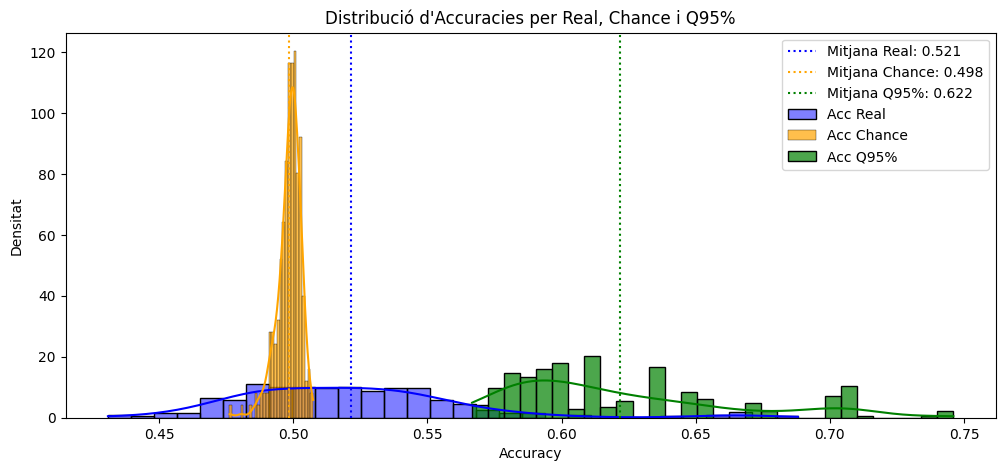

In [16]:
# Histograma acc_real_mean, acc_chance_mean i acc_chance_q95 amb seaborn
plt.figure(figsize=(12, 5))
sns.histplot(df_epochs, x="acc_real_mean", color="blue", label="Acc Real", kde=True, stat="density", bins=30)
sns.histplot(
    df_epochs, x="acc_chance_mean", color="orange", label="Acc Chance", kde=True, stat="density", bins=30, alpha=0.7
)
sns.histplot(
    df_epochs, x="acc_chance_q95", color="green", label="Acc Q95%", kde=True, stat="density", bins=30, alpha=0.7
)
plt.title("Distribució d'Accuracies per Real, Chance i Q95%")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
# Ensenya mitjanes dels tres grups
mean_real = df_epochs["acc_real_mean"].mean()
mean_chance = df_epochs["acc_chance_mean"].mean()
mean_q95 = df_epochs["acc_chance_q95"].mean()

plt.axvline(mean_real, color="blue", linestyle=":", label=f"Mitjana Real: {mean_real:.3f}")
plt.axvline(mean_chance, color="orange", linestyle=":", label=f"Mitjana Chance: {mean_chance:.3f}")
plt.axvline(mean_q95, color="green", linestyle=":", label=f"Mitjana Q95%: {mean_q95:.3f}")
plt.legend()
plt.savefig(FIGURES_DIR / f"histogram_epochs_{TASK_TAG}.png")
plt.show()

### 4b. Resum numèric epochs → accuracy (sense figures)

Aquesta cel·la deixa només el resum numèric de la graella.
Totes les figures queden centralitzades a l'apartat 7.

In [17]:
# Resum numèric de la graella d'epochs
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

df_surpass = df_epochs[df_epochs["acc_real_mean"] > df_epochs["acc_chance_q95"]]

print("Resum de rendiment (graella epochs):")
print(f"- Files totals: {len(df_epochs)}")
print(f"- Subjectes únics: {df_epochs['subject'].nunique()}")
print(f"- Elèctrodes únics: {df_epochs['electrode'].nunique()}")
print(f"- n_epochs provats: {sorted(df_epochs['n_epochs_total'].unique().tolist())}")
print(f"- Acc real mitjana global: {df_epochs['acc_real_mean'].mean():.4f}")
print(f"- Chance q95 mitjana global: {df_epochs['acc_chance_q95'].mean():.4f}")

if not df_surpass.empty:
    print(f"- Mínim d'epochs per superar q95: {int(df_surpass['n_epochs_total'].min())}")
    print(
        f"- Combinacions que superen q95: {len(df_surpass)}/{len(df_epochs)} "
        f"({100*len(df_surpass)/len(df_epochs):.1f}%)"
    )
else:
    print("- Cap combinació supera el chance q95 en la graella actual.")

display(grp.head(10))

Resum de rendiment (graella epochs):
- Files totals: 240
- Subjectes únics: 30
- Elèctrodes únics: 1
- n_epochs provats: [20, 40, 60, 80, 100, 120, 140, 160, 180]
- Acc real mitjana global: 0.5214
- Chance q95 mitjana global: 0.6218
- Mínim d'epochs per superar q95: 40
- Combinacions que superen q95: 11/240 (4.6%)


,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95
0,20,0.500556,0.116087,0.491211,0.709074
1,40,0.504200,0.087284,0.497772,0.658910
2,60,0.527833,0.074962,0.500119,0.631194
3,80,0.519674,0.059098,0.499526,0.615448
4,100,0.528985,0.052765,0.498965,0.601032
5,120,0.526092,0.048071,0.500680,0.595460
6,140,0.528670,0.041576,0.499070,0.586876
7,160,0.533486,0.035133,0.500090,0.579746
8,180,0.533450,0.035405,0.499796,0.577807


## 5. Mapa temps×elèctrode (càlcul paral·lel)

### Nota sobre les features per finestra
Cada finestra de `MAP_WINDOW_SEC` és classificada usant **tots els punts temporals
de la finestra** com a features (matriu `trials × win_samples` al LR).
Això és molt més informatiu que usar la mitjana (1 feature), però augmenta el
cost computacional — d'aquí la necessitat del paral·lelisme.


In [18]:
subject_ids = pd.unique(subj_list).tolist()

# Defineix finestres temporals
time_step = float(np.median(np.diff(times)))
sfreq_est = 1.0 / time_step
win_samples = max(2, int(round(MAP_WINDOW_SEC * sfreq_est)))
step_samples = max(1, int(round(MAP_STEP_SEC * sfreq_est)))

starts = np.arange(0, len(times) - win_samples + 1, step_samples)
stops = starts + win_samples
window_centers = np.array([times[s:e].mean() for s, e in zip(starts, stops)], dtype=np.float32)
n_w, n_bands = len(window_centers), len(CHANNEL_MODE)

print(f"Finestres: {n_w} | amplada={MAP_WINDOW_SEC*1000:.0f}ms, pas={MAP_STEP_SEC*1000:.0f}ms")
print(f"Clústers (Bandes): {n_bands} | Subjectes: {len(subject_ids)}")
print(f"Features: covariància sobre cadascuna de les mostres de la finestra.")
print(
    f"Total de surrogates a calcular: {len(subject_ids)} × {n_bands} × {n_w} × {N_PERM_SURROGATE:,} = "
    f"{len(subject_ids)*n_bands*n_w*N_PERM_SURROGATE:,}"
)

Finestres: 11 | amplada=500ms, pas=100ms
Clústers (Bandes): 1 | Subjectes: 30
Features: covariància sobre cadascuna de les mostres de la finestra.
Total de surrogates a calcular: 30 × 1 × 11 × 200 = 66,000


In [19]:
subject_ids = pd.unique(subj_list).tolist()

print("Executant mapa temps×clúster (paral·lel per subjectes) …")
print(f"Subjectes: {len(subject_ids)}")

if not RECALCULAR_CHANCE_LEVEL and CACHE_MAP_FILE.exists():
    print(f"Carregant mapa temps×clúster des de cache: {CACHE_MAP_FILE}")
    map_data = np.load(CACHE_MAP_FILE)
    real_map = map_data["real_map"]
    surr_mean = map_data["surr_mean"]
    surr_q95 = map_data["surr_q95"]
else:
    print("Recalculant mapa temps×clúster (permutacions) …")
    results = Parallel(n_jobs=N_JOBS)(
        delayed(_process_subject)(si, subj, X_dict, y, subj_list, CHANNEL_MODE, starts, stops)
        for si, subj in enumerate(subject_ids)
    )

    # Reassembla tensors (n_subj, n_bands, n_w)
    real_map = np.stack([r[0] for r in results], axis=0)  # (S, C, W)
    surr_mean = np.stack([r[1] for r in results], axis=0)
    surr_q95 = np.stack([r[2] for r in results], axis=0)
    np.savez_compressed(CACHE_MAP_FILE, real_map=real_map, surr_mean=surr_mean, surr_q95=surr_q95)
    print(f"Desat mapa temps×clúster a cache: {CACHE_MAP_FILE}")

delta_map = real_map - surr_mean  # ΔAcc(s, ch, t)
above_q95_map = real_map > surr_q95  # bool(s, ch, t)

print(f"Tensors shape: real_map={real_map.shape}  (subj, clúster, finestra)")

Executant mapa temps×clúster (paral·lel per subjectes) …
Subjectes: 30
Recalculant mapa temps×clúster (permutacions) …
Desat mapa temps×clúster a cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\cache\tensors_map_im_vs_ip_riemann_fused.npz
Tensors shape: real_map=(30, 1, 11)  (subj, clúster, finestra)


## 6. Estadística de grup: paired t-test per cel·la (canal, t)

Per a cada cel·la $(ch, t)$ comparem:
- **real_map[:, ch, t]**: accuracy real de cada subjecte
- **surr_mean[:, ch, t]**: accuracy de chance (surrogate mean) del mateix subjecte

Hipòtesi H₁ (one-tailed): Acc_real > Acc_chance → només p/2 si t > 0.
Criteri final robust: `p < 0.05` **i** `ΔAcc_grupal > 0` **i** `hit-rate ≥ 0.50`.


In [20]:
n_subj_arr = real_map.shape[0]
p_map = np.full((n_bands, n_w), np.nan, dtype=np.float64)
t_map = np.full((n_bands, n_w), np.nan, dtype=np.float64)

for b_idx in range(n_bands):
    for wi in range(n_w):
        a = real_map[:, b_idx, wi]
        b = surr_mean[:, b_idx, wi]
        valid = ~np.isnan(a) & ~np.isnan(b)
        if valid.sum() < 6:
            continue
        t_stat, p_two = ttest_rel(a[valid], b[valid])
        t_map[b_idx, wi] = t_stat
        # One-tailed: p/2 si t > 0 (direccional: real > chance)
        p_map[b_idx, wi] = (p_two / 2) if t_stat > 0 else 1.0

mean_delta_map = np.nanmean(delta_map, axis=0)  # (n_bands, n_w)
hit_rate_map = np.nanmean(above_q95_map.astype(float), axis=0)

sig_map = (p_map < 0.05) & (mean_delta_map > 0)

# Onset per clúster: primer instant amb superació significativa
onset_time_per_ch = np.full(n_bands, np.nan, dtype=np.float32)
for b_idx in range(n_bands):
    sig_idx = np.where(sig_map[b_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_ch[b_idx] = float(window_centers[sig_idx[0]])

# Criteri robust: p<0.05 + ΔAcc>0 + hit-rate≥0.5
robust_map = sig_map & (hit_rate_map >= 0.50)

n_sig = int(np.sum(sig_map))
n_rob = int(np.sum(robust_map))
print(f"Cel·les significatives (p<0.05, ΔAcc>0): {n_sig} / {n_bands*n_w}")
print(f"Cel·les robustes (+hit-rate≥0.5):         {n_rob} / {n_bands*n_w}")

Cel·les significatives (p<0.05, ΔAcc>0): 7 / 11
Cel·les robustes (+hit-rate≥0.5):         0 / 11


## 7. Visualitzacions

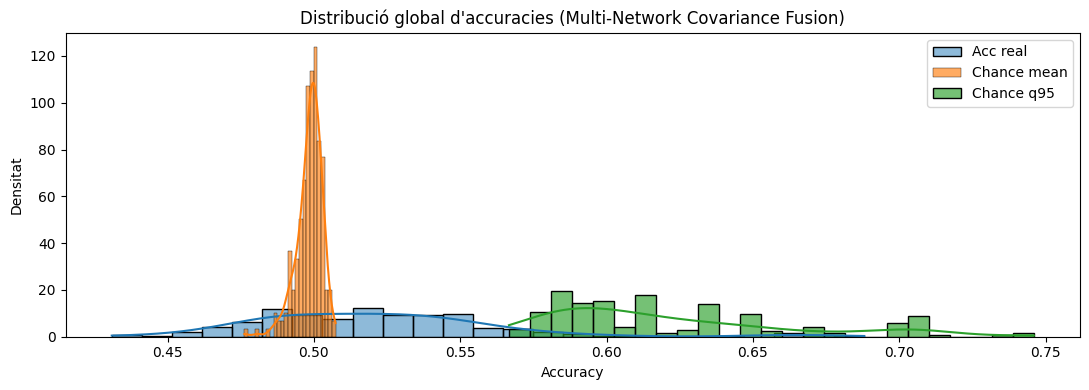

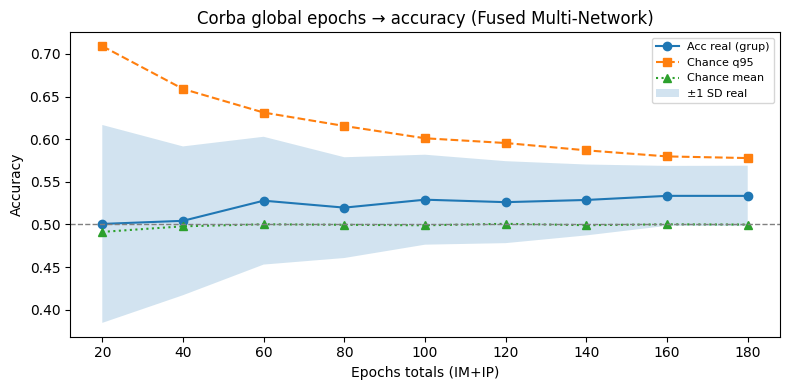

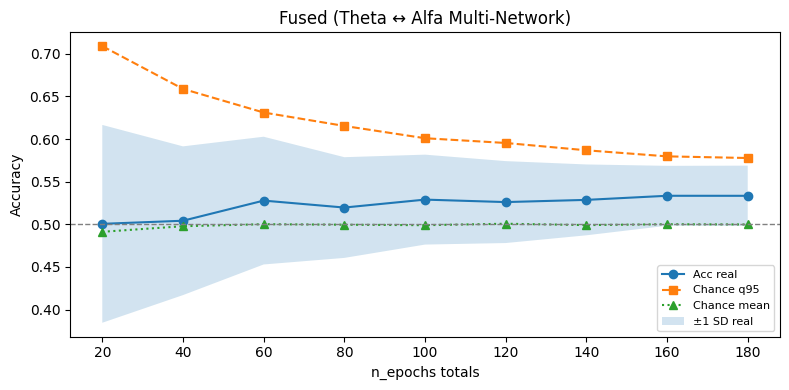

In [21]:
target_electrodes = CHANNEL_MODE  # ["fused"] per a multi-network
df_two = df_epochs[df_epochs["electrode"].isin(target_electrodes)].copy()

# 7a) Distribucions globals (real vs chance)
plt.figure(figsize=(11, 4))
sns.histplot(df_epochs, x="acc_real_mean", color="tab:blue", label="Acc real", kde=True, stat="density", bins=25)
sns.histplot(
    df_epochs,
    x="acc_chance_mean",
    color="tab:orange",
    label="Chance mean",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
sns.histplot(
    df_epochs,
    x="acc_chance_q95",
    color="tab:green",
    label="Chance q95",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
plt.title("Distribució global d'accuracies (Multi-Network Covariance Fusion)")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07a_dist_accuracies_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7b) Corba epochs -> accuracy (grup)
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(8, 4))
plt.plot(grp["n_epochs_total"], grp["acc_real_mean"], "o-", label="Acc real (grup)")
plt.plot(grp["n_epochs_total"], grp["acc_chance_q95"], "s--", label="Chance q95")
plt.plot(grp["n_epochs_total"], grp["acc_chance_mean"], "^:", label="Chance mean")
plt.fill_between(
    grp["n_epochs_total"],
    grp["acc_real_mean"] - grp["acc_real_std"],
    grp["acc_real_mean"] + grp["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
plt.xlabel("Epochs totals (IM+IP)")
plt.ylabel("Accuracy")
plt.title("Corba global epochs → accuracy (Fused Multi-Network)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07b_epochs_accuracy_curve_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7c) Corbes per electròde (només "fused")
fig, ax = plt.subplots(figsize=(8, 4))
d = df_two
g = (
    d.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
    )
    .reset_index()
)

ax.plot(g["n_epochs_total"], g["acc_real_mean"], "o-", label="Acc real")
ax.plot(g["n_epochs_total"], g["acc_chance_q95"], "s--", label="Chance q95")
ax.plot(g["n_epochs_total"], g["acc_chance_mean"], "^:", label="Chance mean")
ax.fill_between(
    g["n_epochs_total"],
    g["acc_real_mean"] - g["acc_real_std"],
    g["acc_real_mean"] + g["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
ax.set_title("Fused (Theta ↔ Alfa Multi-Network)")
ax.set_xlabel("n_epochs totals")
ax.set_ylabel("Accuracy")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07c_epochs_accuracy_per_electrode_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

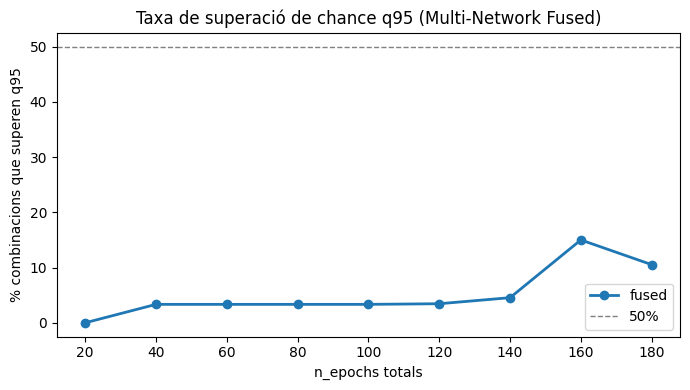

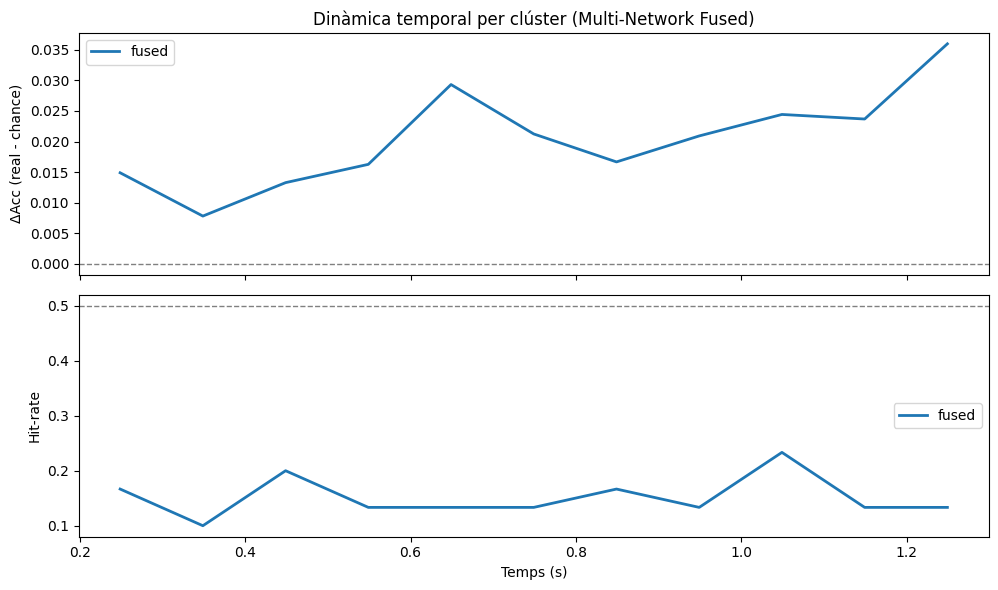


=== RESUM FINAL: Multi-Network Covariance Fusion (Theta ↔ Alfa) ===

fused (9 Theta + 13 Alfa = 22 canals):
  - Combinacions que superen q95: 11/240 (4.6%)
  - ΔAcc mitjà: 0.0229
  - Acc màxima: 0.6881
  → Covariàncies creuades Theta ↔ Alfa capturades a l'espai tangent de Riemann



In [22]:
# 7d) Taxa de superació q95 per electròde
df_two["surpass_q95"] = (df_two["acc_real_mean"] > df_two["acc_chance_q95"]).astype(float)
surpass_tbl = (
    df_two.groupby(["electrode", "n_epochs_total"])["surpass_q95"].mean().unstack("electrode", fill_value=np.nan)
)

fig, ax = plt.subplots(figsize=(7, 4))
for elec in surpass_tbl.columns:
    ax.plot(
        surpass_tbl.index,
        100 * surpass_tbl[elec].values,
        marker="o",
        linewidth=2,
        label=elec,
    )
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="50%")
ax.set_xlabel("n_epochs totals")
ax.set_ylabel("% combinacions que superen q95")
ax.set_title("Taxa de superació de chance q95 (Multi-Network Fused)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07d_surpass_rate_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7e) Dinàmica temporal
ch_to_idx = {ch: i for i, ch in enumerate(CHANNEL_MODE)}
valid_targets = [e for e in target_electrodes if e in ch_to_idx]

if len(window_centers) < 2:
    # Una única finestra temporal
    plt.figure(figsize=(6, 3))
    bars = []
    for elec in valid_targets:
        ci = ch_to_idx[elec]
        bars.append(float(mean_delta_map[ci, 0]))
    plt.bar(valid_targets, bars)
    plt.axhline(0.0, color="gray", linestyle="--", linewidth=1)
    plt.ylabel("ΔAcc (única finestra)")
    plt.title("Resum temporal (1 finestra) - Multi-Network Fused")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07e_temporal_dynamics_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    # Múltiples finestres temporals
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    for elec in valid_targets:
        ci = ch_to_idx[elec]
        axes[0].plot(window_centers, mean_delta_map[ci], linewidth=2, label=elec)
        axes[1].plot(window_centers, hit_rate_map[ci], linewidth=2, label=elec)

    axes[0].axhline(0.0, color="gray", linestyle="--", linewidth=1)
    axes[0].set_ylabel("ΔAcc (real - chance)")
    axes[0].set_title("Dinàmica temporal per clúster (Multi-Network Fused)")
    axes[0].legend()

    axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
    axes[1].set_ylabel("Hit-rate")
    axes[1].set_xlabel("Temps (s)")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07e_temporal_dynamics_fused_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Resum final
print("\n=== RESUM FINAL: Multi-Network Covariance Fusion (Theta ↔ Alfa) ===\n")
for elec in target_electrodes:
    dfe = df_two[df_two["electrode"] == elec]
    surpass = (dfe["acc_real_mean"] > dfe["acc_chance_q95"]).sum()
    total = len(dfe)
    avg_delta = dfe["delta_acc"].mean()
    max_acc = dfe["acc_real_mean"].max()
    print(f"{elec} (9 Theta + 13 Alfa = 22 canals):")
    print(f"  - Combinacions que superen q95: {surpass}/{total} ({100*surpass/total:.1f}%)")
    print(f"  - ΔAcc mitjà: {avg_delta:.4f}")
    print(f"  - Acc màxima: {max_acc:.4f}")
    print(f"  → Covariàncies creuades Theta ↔ Alfa capturades a l'espai tangent de Riemann")
    print()

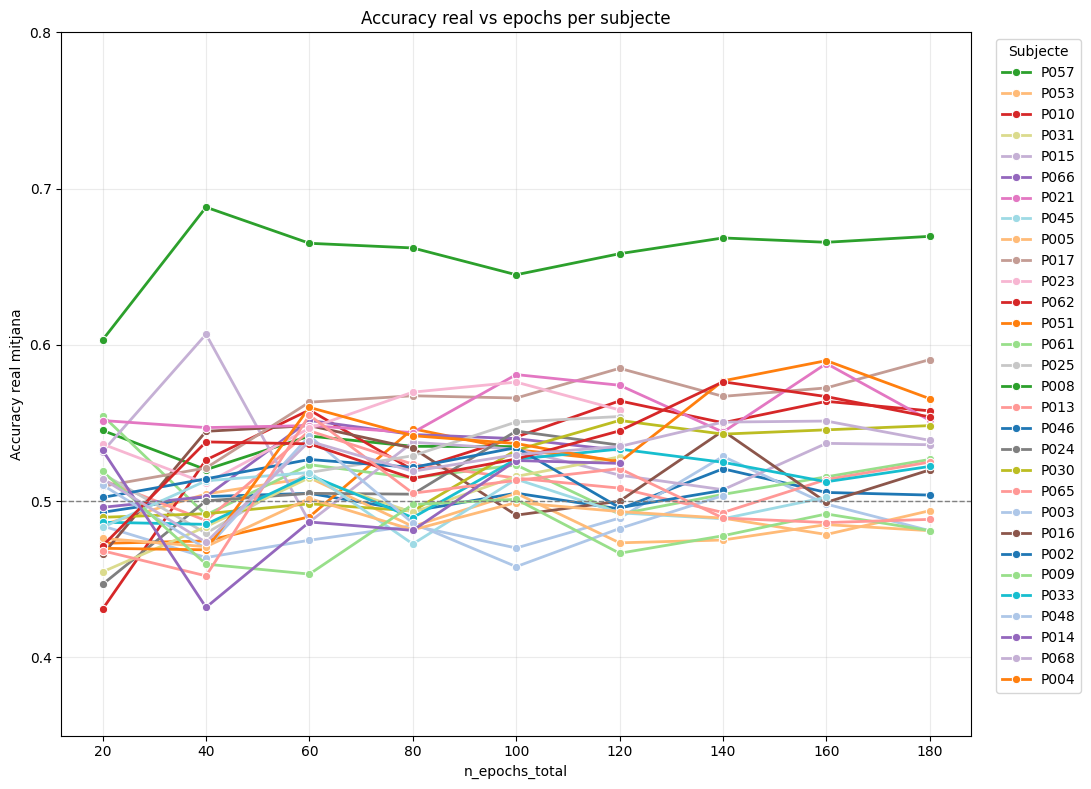

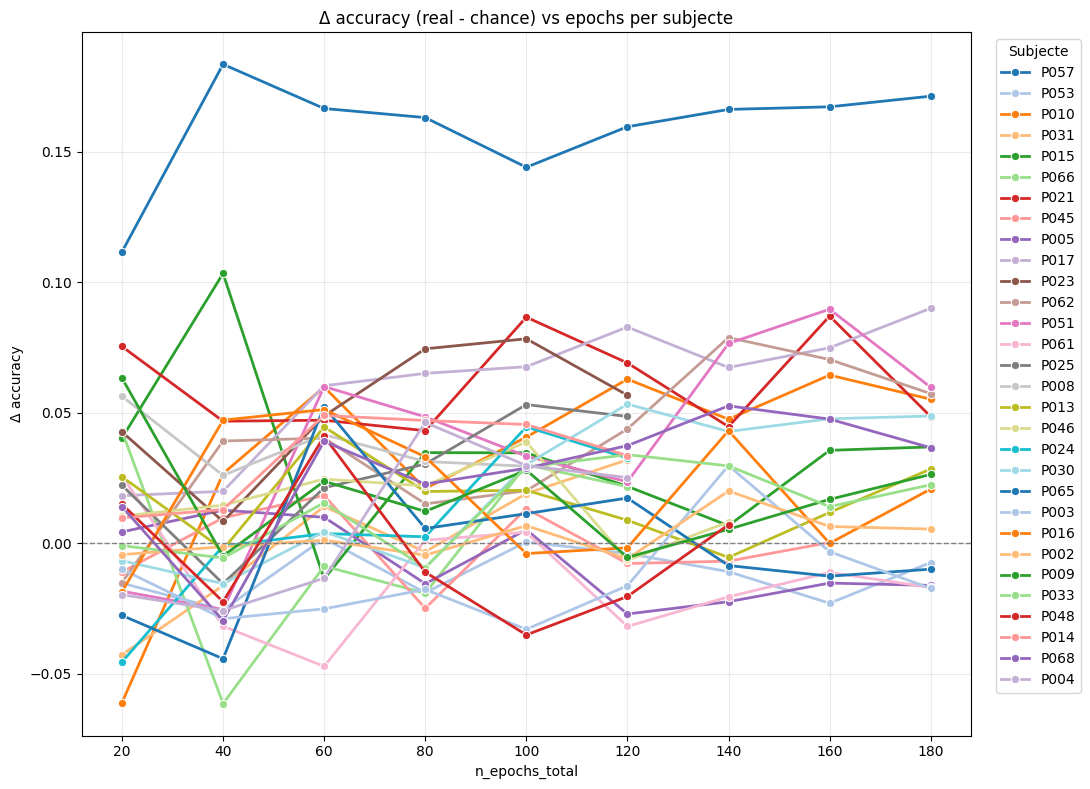

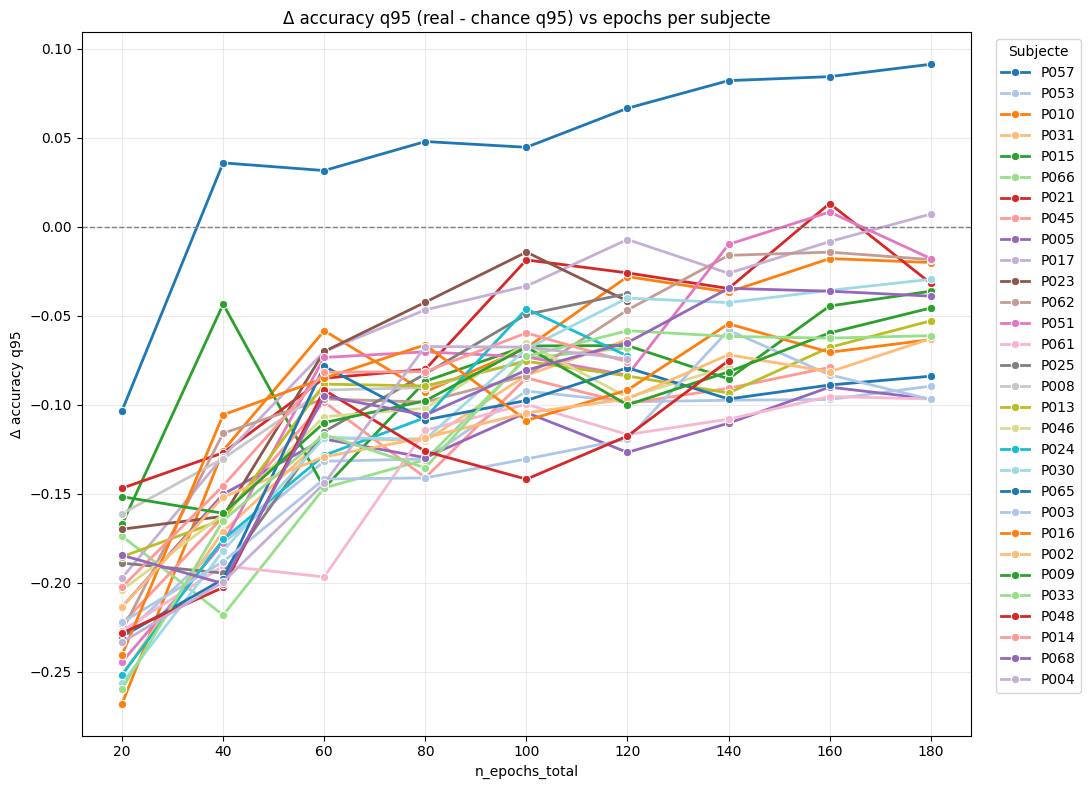

In [32]:
# Accuracy (real) segons nombre d'epochs, amb una línia per subjecte
df_subj_acc = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["acc_real_mean"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 8))
sns.lineplot(
    data=df_subj_acc,
    x="n_epochs_total",
    y="acc_real_mean",
    hue="subject",
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.title("Accuracy real vs epochs per subjecte")
plt.xlabel("n_epochs_total")
plt.ylabel("Accuracy real mitjana")
plt.ylim(0.35, 0.8)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.grid(alpha=0.25)
subject_order = [s for s in pd.unique(subj_list) if s in df_subj_acc["subject"].unique()]

# Reordena la llegenda del primer plot segons subj_list
fig1 = plt.gcf()
ax1 = plt.gca()
handles, labels = ax1.get_legend_handles_labels()
hmap = {lab: h for h, lab in zip(handles, labels)}
ordered_labels = [s for s in subject_order if s in hmap]
ordered_handles = [hmap[s] for s in ordered_labels]
ax1.legend(ordered_handles, ordered_labels, title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Plot extra: delta accuracy vs epochs per subjecte
df_subj_delta = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["delta_acc"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 8))
sns.lineplot(
    data=df_subj_delta,
    x="n_epochs_total",
    y="delta_acc",
    hue="subject",
    hue_order=subject_order,
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Δ accuracy (real - chance) vs epochs per subjecte")
plt.xlabel("n_epochs_total")
plt.ylabel("Δ accuracy")
plt.grid(alpha=0.25)
plt.legend(title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Plot extra: delta accuracy q95 vs epochs per subjecte
df_subj_delta_q95 = (
    df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)["delta_acc_q95"]
    .mean()
    .sort_values(["subject", "n_epochs_total"])
)

plt.figure(figsize=(11, 8))
sns.lineplot(
    data=df_subj_delta_q95,
    x="n_epochs_total",
    y="delta_acc_q95",
    hue="subject",
    hue_order=subject_order,
    palette="tab20",
    marker="o",
    linewidth=2,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Δ accuracy q95 (real - chance q95) vs epochs per subjecte")
plt.xlabel("n_epochs_total")
plt.ylabel("Δ accuracy q95")
plt.grid(alpha=0.25)
plt.legend(title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

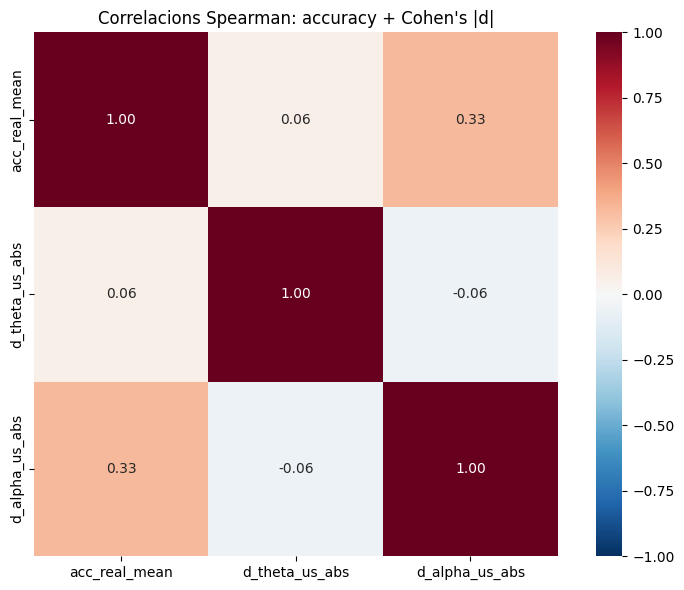

Matriu Spearman desada a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\im_vs_ip_riemann\figures


In [24]:
# 7f) Matriu de correlació (Spearman) amb Cohen's |d| només

acc_cols = ["acc_real_mean"]
acc_cols = [c for c in acc_cols if c in df_epochs.columns]
if len(acc_cols) == 0:
    raise RuntimeError("No s'han trobat columnes d'accuracy a df_epochs per calcular correlacions.")

# Resum per subjecte per evitar duplicacions per n_epochs/electrode
df_acc_subject = df_epochs.groupby("subject", as_index=False)[acc_cols].mean().sort_values("subject")

# Metadades de selecció
df_meta = pd.read_csv(SELECTED_SUBJECTS_CSV).copy()
df_meta["subject"] = df_meta["subjecte"].astype(str)

# Només columnes de Cohen's |d|
cohen_cols = [c for c in ["d_theta_us_abs", "d_alpha_us_abs"] if c in df_meta.columns]
if len(cohen_cols) == 0:
    raise RuntimeError("No s'han trobat columnes de Cohen's |d| al CSV de selecció.")

for c in cohen_cols:
    df_meta[c] = pd.to_numeric(df_meta[c], errors="coerce")

df_corr_base = df_acc_subject.merge(df_meta[["subject"] + cohen_cols], on="subject", how="left")

corr_cols = acc_cols + cohen_cols
corr_spearman = df_corr_base[corr_cols].corr(method="spearman", numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlacions Spearman: accuracy + Cohen's |d|")
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07f_correlacio_spearman_accuracy_cohens_d_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Matriu Spearman desada a: {FIGURES_DIR}")

In [ ]:
# 7g) Global model weights and spatial interpretation


def _resolve_topomap_names(n_sensors):
    if "ch_names_dict" in globals() and isinstance(ch_names_dict, dict):
        for key in ("fused", "all", "common", "channels"):
            value = ch_names_dict.get(key)
            if isinstance(value, (list, tuple, np.ndarray)) and len(value) == n_sensors:
                names = list(value)
                return names, names
        for value in ch_names_dict.values():
            if isinstance(value, (list, tuple, np.ndarray)) and len(value) == n_sensors:
                names = list(value)
                return names, names
    if "ch_names" in globals() and isinstance(ch_names, (list, tuple, np.ndarray)) and len(ch_names) == n_sensors:
        names = list(ch_names)
        return names, names
    if (
        "target_electrodes" in globals()
        and isinstance(target_electrodes, (list, tuple, np.ndarray))
        and len(target_electrodes) == n_sensors
    ):
        names = list(target_electrodes)
        return names, names
    fallback = [f"ch{i}" for i in range(n_sensors)]
    return fallback, fallback


def _weights_from_classifier(model, n_sensors):
    final_estimator = model.steps[-1][1] if hasattr(model, "steps") else model
    coef = np.asarray(getattr(final_estimator, "coef_", np.array([]))).ravel()
    if coef.size == 0:
        return np.zeros(n_sensors, dtype=float)
    if coef.size == n_sensors:
        return coef.astype(float)
    tri_size = n_sensors * (n_sensors + 1) // 2
    if coef.size == tri_size:
        weights = np.zeros(n_sensors, dtype=float)
        k = 0
        for i in range(n_sensors):
            for j in range(i, n_sensors):
                value = float(abs(coef[k]))
                if i == j:
                    weights[i] += value
                else:
                    weights[i] += 0.5 * value
                    weights[j] += 0.5 * value
                k += 1
        return weights
    return np.abs(np.resize(coef, n_sensors)).astype(float)


if "X_dict" not in globals() or "y" not in globals() or "fused" not in X_dict:
    print("Missing fused X/y for the interpretation plot.")
else:
    X_source = np.asarray(X_dict["fused"], dtype=np.float32)
    model = make_clf()
    model.fit(X_source, y)

    sensor_names, display_names = _resolve_topomap_names(X_source.shape[1])
    if len(sensor_names) != X_source.shape[1]:
        sensor_names = [f"ch{i}" for i in range(X_source.shape[1])]
        display_names = sensor_names

    weights = _weights_from_classifier(model, len(sensor_names))
    weights = np.nan_to_num(weights.astype(float), nan=0.0)

    info = mne.create_info(sensor_names, sfreq=1.0, ch_types="eeg")
    try:
        info.set_montage("standard_1020", on_missing="ignore")
    except Exception:
        pass

    fig, ax = plt.subplots(figsize=(6.8, 5.8))
    try:
        im, _ = mne.viz.plot_topomap(weights, info, axes=ax, show=False, cmap="RdBu_r", contours=0)
        fig.colorbar(im, ax=ax, shrink=0.8, label="Weight")
        ax.set_title("Global fused-model weights")
    except Exception:
        order = np.argsort(np.abs(weights))[::-1]
        ax.bar(
            np.arange(len(order)), weights[order], color=["tab:red" if weights[i] >= 0 else "tab:blue" for i in order]
        )
        ax.set_xticks(np.arange(len(order)))
        ax.set_xticklabels([display_names[i] for i in order], rotation=45, ha="right")
        ax.set_ylabel("Weight")
        ax.set_title("Global fused-model weights")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_fused_model_weights_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()

    fig = plt.figure(figsize=(7.5, 6.5))
    ax3d = fig.add_subplot(111, projection="3d")
    coords = np.array([ch["loc"][:3] for ch in info["chs"]], dtype=float)
    finite = np.isfinite(coords).all(axis=1) & (np.linalg.norm(coords, axis=1) > 0)
    if not np.any(finite):
        theta = np.linspace(0, 2 * np.pi, len(sensor_names), endpoint=False)
        coords = np.column_stack([np.cos(theta), np.sin(theta), np.zeros_like(theta)])
        finite = np.ones(len(sensor_names), dtype=bool)
    coords = coords[finite]
    weights_3d = weights[finite]
    finite_display_names = np.asarray(display_names)[finite]
    sizes = 120 + 700 * (np.abs(weights_3d) / (np.max(np.abs(weights_3d)) + 1e-12))
    sc = ax3d.scatter(coords[:, 0], coords[:, 1], coords[:, 2], c=weights_3d, s=sizes, cmap="RdBu_r", depthshade=True)
    for idx in np.argsort(np.abs(weights_3d))[::-1][: min(5, len(weights_3d))]:
        ax3d.text(coords[idx, 0], coords[idx, 1], coords[idx, 2], finite_display_names[idx], fontsize=8)
    fig.colorbar(sc, ax=ax3d, shrink=0.75, pad=0.08, label="Weight")
    ax3d.set_title("3D sensor-weight view")
    ax3d.set_axis_off()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_fused_model_weights_3d_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()

    top_n = min(10, len(weights))
    order = np.argsort(np.abs(weights))[::-1][:top_n]
    fig, ax = plt.subplots(figsize=(8.5, max(3.0, 0.42 * top_n + 1.0)))
    sns.barplot(x=weights[order], y=[display_names[i] for i in order], palette="vlag", orient="h", ax=ax)
    ax.axvline(0.0, color="0.5", linewidth=1)
    ax.set_title("Top fused-model sensor weights")
    ax.set_xlabel("Weight")
    ax.set_ylabel("Sensor")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_fused_model_weights_bar_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()